# What Makes a YouTube Video Trend? A Data Story for Creators

2026-11-06

This notebook studies daily trending-video records to answer creator-friendly questions: which categories and regions appear most often, how views and engagement rates differ, how long videos tend to be published before trending, and whether simple metadata available before performance can benchmark high engagement. The goal is a useful data story, not a claim that any single title formula guarantees virality.

The analysis uses the two CSV files included in this project's `data/` folder: `USvideos.csv` and `INvideos.csv`. All numerical results are calculated from those files when the notebook is run.


## 1. Setup and repository data loading

Place `USvideos.csv` and `INvideos.csv` in the repository's `data/` folder. This loader searches the common repository locations so the notebook can be run either from the project root or from the `notebooks/` folder. It reads the CSV files using the source encoding and combines the available regional records.


In [ ]:
from pathlib import Path
import sys, warnings, json

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)

for package in ["numpy", "pandas", "matplotlib", "seaborn", "sklearn"]:
    __import__(package)

print("Python:", sys.version.split()[0], "| imports validated")

# The notebook is expected to be in the notebooks/ folder and the CSV files
# in the repository's data/ folder. These paths also work when Jupyter is
# launched from the repository root.
roots = [
    Path.cwd() / "data",
    Path.cwd().parent / "data",
    Path.cwd(),
    Path.cwd().parent,
]

frames = []
for region in ["US", "IN"]:
    hits = []
    for root in roots:
        if root.exists():
            hits.extend(root.glob(f"{region}videos.csv"))
            hits.extend(root.glob(f"**/{region}videos.csv"))
    # Remove duplicate paths while preserving order.
    hits = list(dict.fromkeys(hits))

    if hits:
        csv_path = hits[0]
        data = pd.read_csv(csv_path, encoding="latin1")
        data["region"] = region
        frames.append(data)
        print(region, "->", csv_path, data.shape)

if not frames:
    raise FileNotFoundError(
        "Could not find USvideos.csv and INvideos.csv. "
        "Place both files in the repository's data/ folder."
    )

df = pd.concat(frames, ignore_index=True)
print("Combined shape:", df.shape)
display(df.head())


## 2. Schema and feature construction

The dataset contains repeated daily observations for videos that remain on the trending list. We create descriptive features from publication and trending timestamps, title/tags, and engagement counts. The performance metrics are kept separate from the pre-performance metadata used by the benchmark model.

In [2]:
expected=['video_id','trending_date','title','channel_title','category_id','publish_time','tags','views','likes','dislikes','comment_count','thumbnail_link','comments_disabled','ratings_disabled','video_error_or_removed','description','region']; assert list(df.columns)==expected; df["trending_date_parsed"]=pd.to_datetime(df.trending_date,format="%y.%d.%m",errors="coerce"); df["publish_dt"]=pd.to_datetime(df.publish_time,errors="coerce",utc=True); assert df.publish_dt.notna().all(); df["days_to_trend"]=(df.trending_date_parsed.dt.tz_localize("UTC")-df.publish_dt.dt.normalize()).dt.total_seconds()/86400; df["title_chars"]=df.title.fillna("").str.len(); df["title_words"]=df.title.fillna("").str.split().str.len(); df["tag_count"]=df.tags.fillna("").replace("[none]","").str.count("\|")+df.tags.fillna("").ne(""); df["publish_hour"]=df.publish_dt.dt.hour; df["like_rate"]=df.likes/df.views.replace(0,np.nan); df["comment_rate"]=df.comment_count/df.views.replace(0,np.nan); df=df.replace([np.inf,-np.inf],np.nan); print("Rows:",len(df),"| unique videos:",df.video_id.nunique(),"| duplicate rows:",int(df.duplicated().sum())); display(df[['views','likes','comment_count','days_to_trend','title_chars','like_rate','comment_rate']].describe(percentiles=[.1,.5,.9,.99]).round(4))

Rows: 78301 | unique videos: 22427 | duplicate rows: 4311


,views,likes,comment_count,days_to_trend,title_chars,like_rate,comment_rate
count,7.830100e+04,7.830100e+04,7.830100e+04,78301.0000,78301.0000,78301.0000,78301.0000
mean,1.740498e+06,5.175848e+04,5.694428e+03,9.7871,70.1247,0.0285,0.0036
std,5.818295e+06,1.801511e+05,2.909385e+04,105.8573,44.7991,0.0284,0.0072
min,5.490000e+02,0.000000e+00,0.000000e+00,0.0000,3.0000,0.0000,0.0000
10%,6.197700e+04,4.260000e+02,3.800000e+01,1.0000,29.0000,0.0033,0.0003
50%,4.562340e+05,8.687000e+03,8.970000e+02,3.0000,59.0000,0.0201,0.0020
90%,3.446486e+06,1.149570e+05,1.092000e+04,10.0000,122.0000,0.0655,0.0079
99%,2.134466e+07,6.926310e+05,6.786600e+04,24.0000,231.0000,0.1282,0.0234
max,2.252119e+08,5.613827e+06,1.361580e+06,4215.0000,281.0000,0.3819,0.3924


## 3. What appears on the trending list?

The first view is descriptive: a trending-list appearance is not the same as total platform popularity. Category IDs are retained because the JSON category maps vary by region; the notebook compares regions and the most frequent IDs without inventing labels.

,records,unique_videos,median_views,median_like_rate
region,,,,
IN,37352,16307,304586.0,0.0095
US,40949,6351,681861.0,0.0283


,region,category_id,records,median_views,median_like_rate
9,IN,24,16712,276843.0,0.0065
10,IN,25,5241,191731.0,0.0056
2,IN,10,3858,885955.0,0.0215
8,IN,23,3429,477909.0,0.0510
7,IN,22,2624,272068.0,0.0061
0,IN,1,1658,781855.5,0.0166
12,IN,27,1227,51391.0,0.0489
11,IN,26,845,279089.0,0.0103
26,US,24,9964,734704.0,0.0228
19,US,10,6472,1434128.0,0.0394


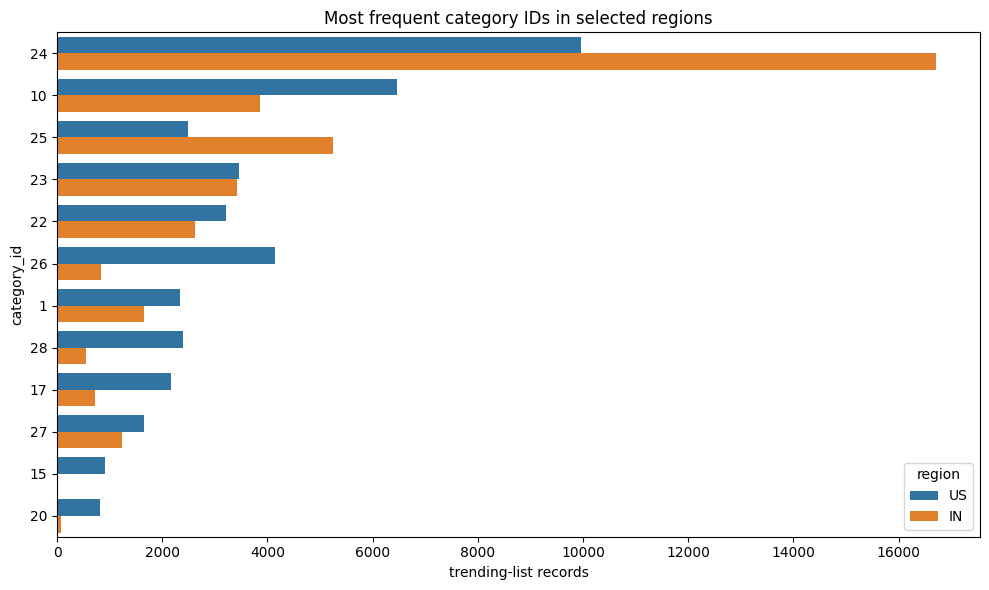

In [3]:
region_stats=df.groupby("region").agg(records=("video_id","size"),unique_videos=("video_id","nunique"),median_views=("views","median"),median_like_rate=("like_rate","median")).round(4); display(region_stats); cat=df.groupby(["region","category_id"]).agg(records=("video_id","size"),median_views=("views","median"),median_like_rate=("like_rate","median")).reset_index(); top_cat=cat.sort_values(["region","records"],ascending=[True,False]).groupby("region").head(8); display(top_cat.round(4)); plt.figure(figsize=(10,6)); sns.countplot(data=df,y="category_id",hue="region",order=df.category_id.value_counts().head(12).index); plt.title("Most frequent category IDs in selected regions"); plt.xlabel("trending-list records"); plt.ylabel("category_id"); plt.tight_layout(); plt.show()

## 4. Engagement: rates matter more than raw counts

Raw views favor large channels and older videos. Like rate and comment rate provide a different lens, although they are also affected by audience mix, video format, and whether viewers are asked to interact. Extreme ratios are not interpreted as causal.

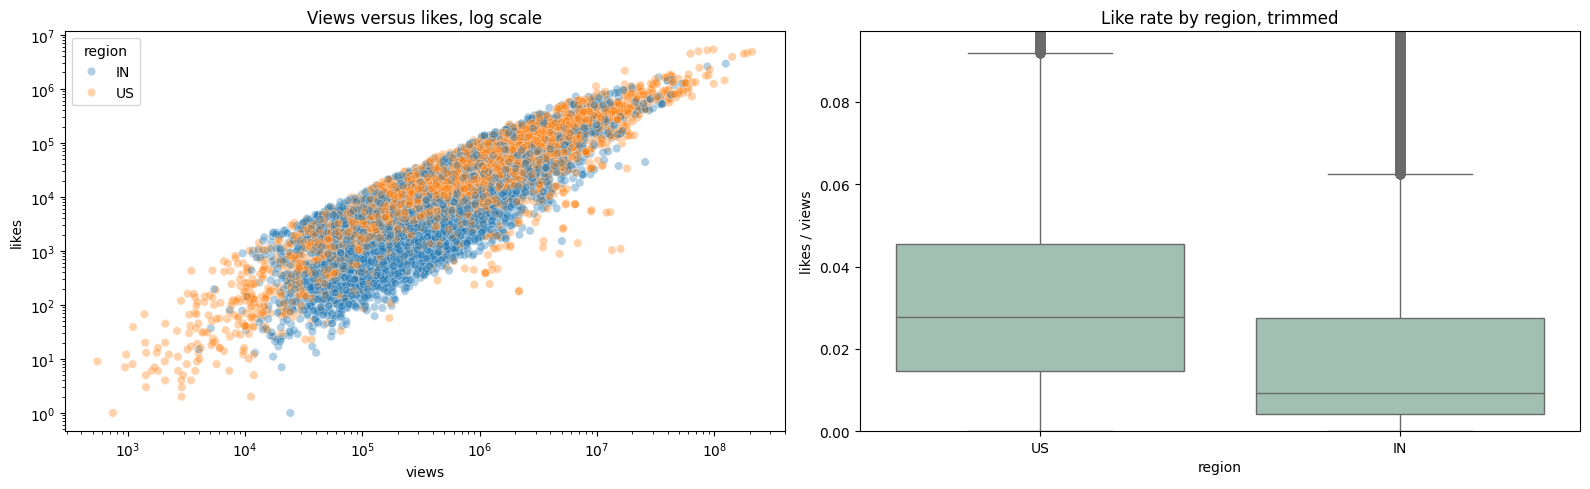

,count,median,mean
region,,,
IN,37352,0.0095,0.0220
US,40949,0.0283,0.0344


In [4]:
plot=df.dropna(subset=["like_rate","comment_rate"]).copy(); plot=plot[(plot.like_rate<=plot.like_rate.quantile(.99))&(plot.comment_rate<=plot.comment_rate.quantile(.99))]; fig,ax=plt.subplots(1,2,figsize=(16,5)); sns.scatterplot(data=plot.sample(min(12000,len(plot)),random_state=42),x="views",y="likes",hue="region",alpha=.35,ax=ax[0]); ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_title("Views versus likes, log scale"); sns.boxplot(data=plot,x="region",y="like_rate",ax=ax[1],color="#9CC4B2"); ax[1].set_ylim(0,plot.like_rate.quantile(.98)); ax[1].set_title("Like rate by region, trimmed"); ax[1].set_ylabel("likes / views"); plt.tight_layout(); plt.show(); display(df.groupby("region")["like_rate"].agg(["count","median","mean"]).round(4))

## 5. Timing and title patterns

A creator can control publishing choices, but the dataset cannot prove that a particular hour or title length causes trending. We compare distributions and medians only. `days_to_trend` is a rough interval because the daily trending date is not an exact recommendation timestamp.

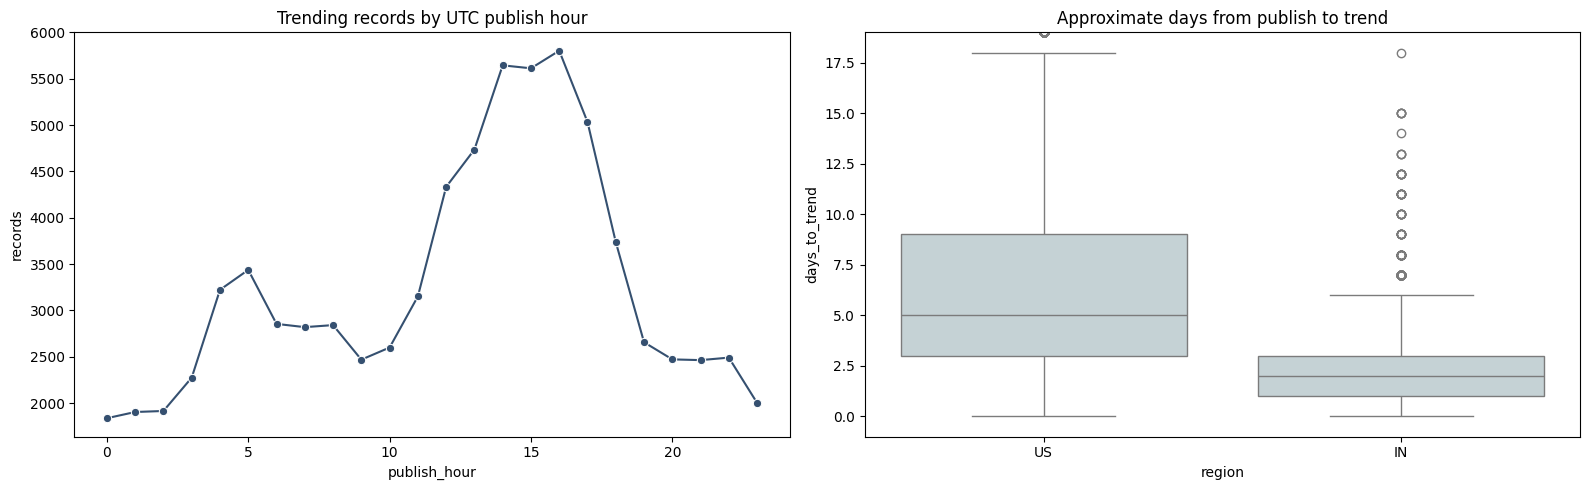

Title length medians by region:


,count,median,mean
region,,,
IN,37352,83.0,93.3
US,40949,47.0,49.0


In [5]:
timing=df.groupby("publish_hour").agg(records=("video_id","size"),median_views=("views","median"),median_like_rate=("like_rate","median")).reset_index(); fig,ax=plt.subplots(1,2,figsize=(16,5)); sns.lineplot(data=timing,x="publish_hour",y="records",marker="o",ax=ax[0],color="#355070"); ax[0].set_title("Trending records by UTC publish hour"); sns.boxplot(data=df,x="region",y="days_to_trend",ax=ax[1],color="#C2D4D8"); ax[1].set_ylim(-1,df.days_to_trend.quantile(.98)); ax[1].set_title("Approximate days from publish to trend"); plt.tight_layout(); plt.show(); print("Title length medians by region:"); display(df.groupby("region")["title_chars"].agg(["count","median","mean"]).round(1))

## 6. Leakage-safe high-engagement benchmark

The target is whether a record’s like rate is at or above the training-set median. The model uses only metadata plausibly available before performance is observed: region, category, publish hour, title length, title word count, tag count, and comments-disabled status. Views, likes, dislikes, comment count, and the target-derived rates are excluded.

Training median like-rate cutoff: 0.02011
ROC AUC: 0.83 | balanced accuracy: 0.757
                 precision    recall  f1-score   support

   Below median       0.77      0.73      0.75      9774
At/above median       0.75      0.78      0.76      9802

       accuracy                           0.76     19576
      macro avg       0.76      0.76      0.76     19576
   weighted avg       0.76      0.76      0.76     19576



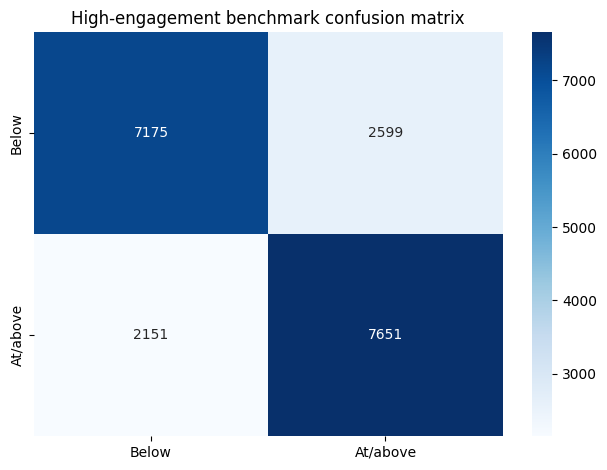

In [6]:
features=["region","category_id","publish_hour","title_chars","title_words","tag_count","comments_disabled"]; work=df.dropna(subset=["like_rate"]+features).copy(); tr,te=train_test_split(np.arange(len(work)),test_size=.25,random_state=42); cutoff=work.iloc[tr].like_rate.median(); y=(work.like_rate>=cutoff).astype(int); cat=["region","category_id"]; num=["publish_hour","title_chars","title_words","tag_count","comments_disabled"]; pre=ColumnTransformer([("cat",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore",min_frequency=3))]),cat),("num",Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num)]); model=Pipeline([("prep",pre),("model",LogisticRegression(max_iter=2500,class_weight="balanced",C=.5,solver="liblinear"))]); model.fit(work.iloc[tr][features],y.iloc[tr]); prob=model.predict_proba(work.iloc[te][features])[:,1]; pred=(prob>=.5).astype(int); print("Training median like-rate cutoff:",round(cutoff,5)); print("ROC AUC:",round(roc_auc_score(y.iloc[te],prob),3),"| balanced accuracy:",round(balanced_accuracy_score(y.iloc[te],pred),3)); print(classification_report(y.iloc[te],pred,target_names=["Below median","At/above median"],zero_division=0)); sns.heatmap(confusion_matrix(y.iloc[te],pred),annot=True,fmt="d",cmap="Blues",xticklabels=["Below","At/above"],yticklabels=["Below","At/above"]); plt.title("High-engagement benchmark confusion matrix"); plt.tight_layout(); plt.show()

## 7. Honest creator takeaways and limitations

The strongest shareable finding should be phrased as a pattern in this trending-list sample, not a promise of virality. The data come from 2017–2018 collection windows and selected regions, and the same video can appear on multiple days. Trending selection is already a filtered outcome, so this is not a random sample of all uploads. Likes and comments are correlated with views and audience size, and the model is a benchmark rather than a recommendation-system replica.

A useful public post can show one category chart, one engagement-rate chart, and one sentence explaining that title length, timing, or tags are associations in the sample—not guaranteed growth levers.

## 8. Reproducibility checklist

- The notebook reads the regional CSV files from the repository's `data/` folder.
- The loader searches common project locations and safely reads the CSV encoding.
- Schema, timestamps, duplicates, and missing performance values are audited.
- Raw performance metrics are kept separate from pre-performance model features.
- The target cutoff is calculated from the training partition only.
- Categorical encoding and imputation are fit inside the pipeline.
- Results are descriptive and non-causal; no universal virality claim is made.
